# Exploratory data analysis: development cohort

**Scope.** 36-month individual loans issued 2013–2015: the train (2013–14) and validation (2015)
splits of `data/interim/cohort.parquet`. The 2016 test split is **not loaded anywhere in this
notebook**, so nothing seen here can leak test information into modeling decisions.

**Questions**
1. How does the default rate move over time?
2. How much signal is in LC's own grade, and is that grade stable?
3. Which application and bureau fields carry signal, and in what shape?
4. What does missingness mean here?
5. What do the distributions say about LC's credit policy?
6. Which fields are redundant?
7. Are the inputs stable between the train and validation years?

Each section ends with a **Takeaway** that feeds a modeling decision. Section 8 collects them.

To rerun: `uv run python -m lc_risk.data.cohort`, then
`uv run jupyter nbconvert --to notebook --execute --inplace discovery/eda.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from lc_risk import config, schema
from lc_risk.data.cohort import load_cohort
from lc_risk.monitoring.drift import psi_table

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = config.TARGET
dev = pd.concat([load_cohort("train"), load_cohort("validation")], ignore_index=True)
assert dev["issue_d"].dt.year.max() < min(config.SPLIT_YEARS["test"]), "test data loaded"

# Two derived quantities explored here; M2 implements them inside the model pipeline.
dev["credit_history_months"] = (dev["issue_d"].dt.year - dev["earliest_cr_line"].dt.year) * 12 + (
    dev["issue_d"].dt.month - dev["earliest_cr_line"].dt.month
)
dev["loan_to_income"] = dev["loan_amnt"] / dev["annual_inc"]
dev["grade"] = dev["sub_grade"].str[0]
dev["year"] = dev["issue_d"].dt.year

print(f"{len(dev):,} loans, default rate {dev[TARGET].mean():.2%}")
dev.groupby("split")[TARGET].agg(loans="size", default_rate="mean")

545,926 loans, default rate 14.07%


,loans,default_rate
split,,
train,262992,0.132
validation,282934,0.149


## 1. Default rate over time

,loans,default_rate
issue_d,,
2013Q1,"17,988",12.6%
2013Q2,"23,136",12.8%
2013Q3,"27,318",12.2%
2013Q4,"31,980",11.9%
2014Q1,"34,074",12.9%
2014Q2,"37,881",13.5%
2014Q3,"40,595",13.6%
2014Q4,"50,020",14.5%
2015Q1,"56,569",14.8%


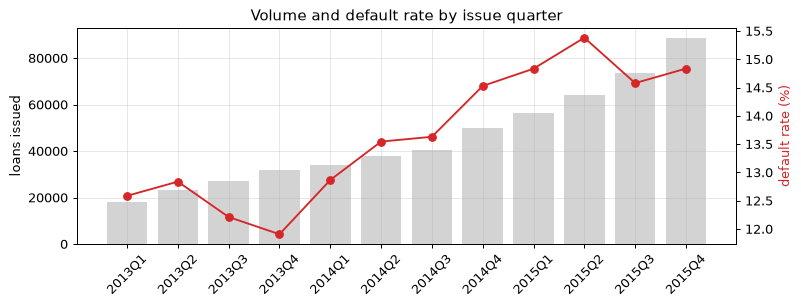

In [2]:
quarterly = dev.groupby(dev["issue_d"].dt.to_period("Q"))[TARGET].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(quarterly.index.astype(str), quarterly["size"], color="lightgray", label="loans issued")
ax.set_ylabel("loans issued")
ax2 = ax.twinx()
ax2.plot(quarterly.index.astype(str), 100 * quarterly["mean"], "o-", color="tab:red")
ax2.set_ylabel("default rate (%)", color="tab:red")
ax2.grid(False)
ax.set_title("Volume and default rate by issue quarter")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
quarterly.rename(columns={"size": "loans", "mean": "default_rate"}).style.format(
    {"loans": "{:,}", "default_rate": "{:.1%}"}
)

**Takeaway.** Volume grew about 5× and the default rate climbed steadily, from about 12.6%
in early 2013 to about 14.8% in late 2015. A model fit on 2013–14 and applied to later loans
will **under-predict** unless its probabilities are recalibrated on the most recent labeled
year. This is why calibration is fit on the 2015 validation year, not on the training years.

## 2. LC's own rating: strong signal, unstable meaning

single-feature AUC  sub_grade 0.667  |  int_rate 0.659


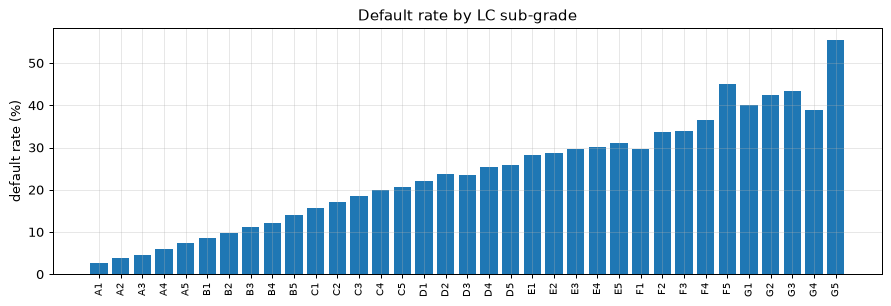

In [3]:
by_subgrade = dev.groupby("sub_grade")[TARGET].agg(["size", "mean"]).reindex(schema.SUB_GRADES)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(by_subgrade.index, 100 * by_subgrade["mean"], color="tab:blue")
ax.set_ylabel("default rate (%)")
ax.set_title("Default rate by LC sub-grade")
ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.tight_layout()

rank = dev["sub_grade"].map({g: i for i, g in enumerate(schema.SUB_GRADES)})
print(
    f"single-feature AUC  sub_grade {roc_auc_score(dev[TARGET], rank):.3f}"
    f"  |  int_rate {roc_auc_score(dev[TARGET], dev['int_rate']):.3f}"
)

In [4]:
mix = pd.crosstab(dev["year"], dev["grade"], normalize="index")
default_by_grade = dev.pivot_table(index="grade", columns="year", values=TARGET, aggfunc="mean")
rate_by_grade = dev.pivot_table(index="grade", columns="year", values="int_rate", aggfunc="mean")
display(mix.style.format("{:.1%}").set_caption("Grade mix by issue year"))
display(default_by_grade.style.format("{:.1%}").set_caption("Default rate by grade and year"))
display(
    rate_by_grade.style.format("{:.2f}").set_caption("Average interest rate (%) by grade and year")
)

grade,A,B,C,D,E,F,G
year,,,,,,,
2013,17.0%,40.1%,24.6%,14.4%,3.2%,0.6%,0.0%
2014,21.7%,32.9%,27.1%,12.6%,4.3%,1.2%,0.1%
2015,24.8%,32.4%,27.3%,11.6%,3.3%,0.5%,0.1%


year,2013,2014,2015
grade,,,
A,4.6%,5.4%,5.4%
B,9.8%,10.7%,11.9%
C,15.3%,17.2%,19.5%
D,20.4%,22.2%,26.2%
E,23.3%,27.0%,32.8%
F,26.8%,29.5%,42.4%
G,26.7%,36.3%,46.2%


year,2013,2014,2015
grade,,,
A,7.70,7.45,6.90
B,11.80,11.19,10.02
C,15.39,14.07,13.24
D,18.66,17.03,16.64
E,21.57,20.32,19.11
F,23.92,24.18,23.54
G,25.75,25.73,26.87


**Takeaway.** `sub_grade` ranks risk well: single-feature AUC ≈ 0.67, versus ≈ 0.60 for the best
bureau field (next section). But its *meaning* drifts. Within every grade the default rate
rose from 2013 to 2015 (grade C: about 15% → 20%), while the share of A loans grew and the
rates for A–C fell. The same letter grade meant more risk each year.

This motivates two decisions:
- **Model A vs Model B.** Measure what the grade adds on top of bureau data, instead of
  assuming it.
- **Monitoring.** An input whose meaning shifts over time is exactly what the monitoring
  stage has to catch.

## 3. Which fields carry signal?

,field,auc,direction,missing
0,fico_range_low,0.599,higher = safer,0.0%
1,acc_open_past_24mths,0.582,higher = riskier,0.0%
2,annual_inc,0.576,higher = safer,0.0%
3,tot_hi_cred_lim,0.575,higher = safer,0.0%
4,bc_open_to_buy,0.575,higher = safer,1.0%
5,total_bc_limit,0.575,higher = safer,0.0%
6,num_tl_op_past_12m,0.574,higher = riskier,0.0%
7,avg_cur_bal,0.572,higher = safer,0.0%
8,dti,0.568,higher = riskier,0.0%
9,total_rev_hi_lim,0.565,higher = safer,0.0%


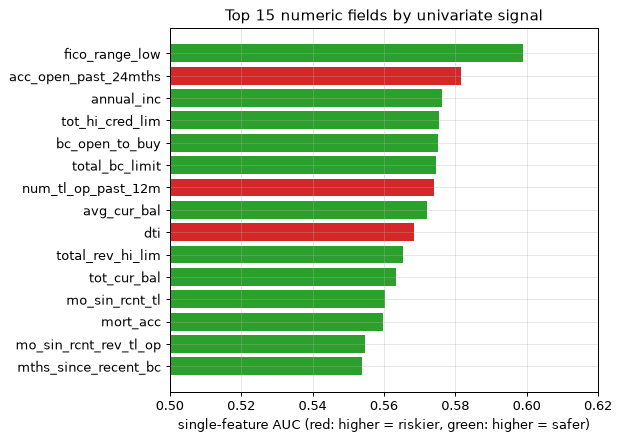

In [5]:
numeric = [f.name for f in schema.APPLICATION_FIELDS if f.kind == "numeric"]
numeric += ["credit_history_months", "loan_to_income"]
rows = []
for name in numeric:
    observed = dev[name].notna()
    auc = roc_auc_score(dev.loc[observed, TARGET], dev.loc[observed, name])
    rows.append(
        {
            "field": name,
            "auc": max(auc, 1 - auc),
            "direction": "higher = riskier" if auc >= 0.5 else "higher = safer",
            "missing": 1 - observed.mean(),
        }
    )
signal = pd.DataFrame(rows).sort_values("auc", ascending=False, ignore_index=True)

top = signal.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["tab:red" if d == "higher = riskier" else "tab:green" for d in top["direction"]]
ax.barh(top["field"], top["auc"], color=colors)
ax.axvline(0.5, color="black", lw=0.8)
ax.set_xlim(0.5, 0.62)
ax.set_xlabel("single-feature AUC (red: higher = riskier, green: higher = safer)")
ax.set_title("Top 15 numeric fields by univariate signal")
fig.tight_layout()
signal.head(15).style.format({"auc": "{:.3f}", "missing": "{:.1%}"})

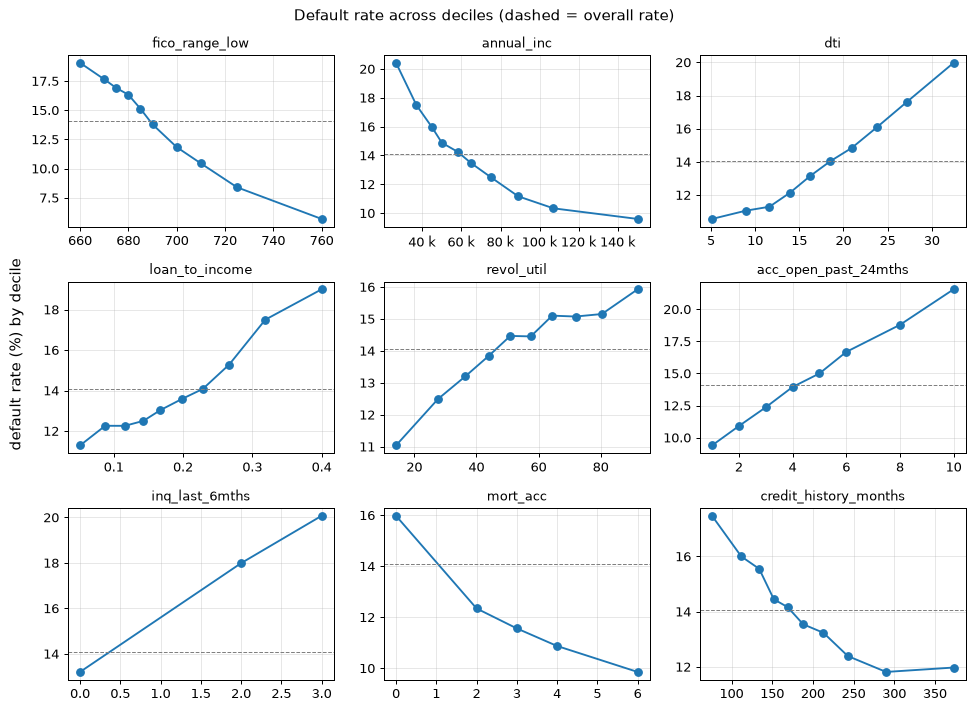

In [6]:
def binned_rate(ax, name, bins=10):
    data = dev[[name, TARGET]].dropna()
    groups = data.groupby(pd.qcut(data[name], bins, duplicates="drop"), observed=True)
    ax.plot(groups[name].median(), 100 * groups[TARGET].mean(), "o-")
    ax.axhline(100 * dev[TARGET].mean(), color="gray", ls="--", lw=0.8)
    ax.set_title(name, fontsize=10)
    if data[name].max() > 10_000:
        ax.xaxis.set_major_formatter(mticker.EngFormatter())


drivers = [
    "fico_range_low",
    "annual_inc",
    "dti",
    "loan_to_income",
    "revol_util",
    "acc_open_past_24mths",
    "inq_last_6mths",
    "mort_acc",
    "credit_history_months",
]
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, name in zip(axes.flat, drivers, strict=True):
    binned_rate(ax, name)
fig.supylabel("default rate (%) by decile")
fig.suptitle("Default rate across deciles (dashed = overall rate)")
fig.tight_layout()

**Takeaway.** No single bureau field comes close to LC's grade; the best (FICO) reaches
AUC ≈ 0.60. The signal is spread over many weak, related fields, which suits gradient-boosted
trees.

The main drivers are **monotonic** and match intuition: higher FICO, income and number of
mortgage accounts mean lower risk, while higher DTI, utilization and recent inquiries or new
accounts mean higher risk. That makes **monotonic constraints** in XGBoost a reasonable
choice. They give up little accuracy and guarantee, for example, that raising FICO never
increases the predicted risk.

## 4. Categorical fields

,loans,default_rate
addr_state,,
NH,2626,0.091
WV,2446,0.107
OR,6998,0.109
NV,8161,0.174
AR,4026,0.175
MS,2472,0.187


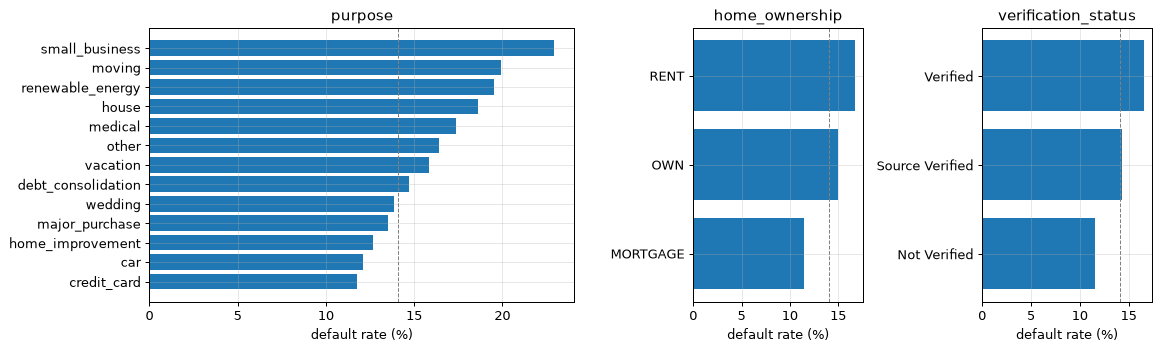

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1.2, 1.2]})
for ax, name in zip(axes, ["purpose", "home_ownership", "verification_status"], strict=True):
    rates = dev.groupby(name)[TARGET].agg(["size", "mean"]).query("size >= 100")
    rates = rates.sort_values("mean")
    ax.barh(rates.index, 100 * rates["mean"], color="tab:blue")
    ax.axvline(100 * dev[TARGET].mean(), color="gray", ls="--", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("default rate (%)")
fig.tight_layout()

states = dev.groupby("addr_state")[TARGET].agg(loans="size", default_rate="mean")
states = states.query("loans >= 2000").sort_values("default_rate")
pd.concat([states.head(3), states.tail(3)])

**Takeaway.** `small_business` and `moving` loans default most and `credit_card`
refinancing the least. Renters default more than mortgage holders.

**Verified income comes with a *higher* default rate.** This is a selection effect, not a
causal one: LC chooses to verify the applicants who already look riskier, so the field
partly encodes LC's own underwriting suspicion. The model may use it, but it should be read
as "LC was suspicious", not as "verification causes defaults".

State-level rates range from about 9% (NH) to about 19% (MS). `addr_state` stays a candidate
with a fairness note: geography can proxy protected characteristics, so its contribution
will be reported separately.

`home_ownership = OTHER` has only 2 loans in these years and carries no usable signal.

## 5. What does a missing value mean?

In [8]:
history = [
    "mths_since_last_delinq",
    "mths_since_last_major_derog",
    "mths_since_recent_bc_dlq",
    "mths_since_recent_revol_delinq",
    "mths_since_last_record",
    "mths_since_recent_inq",
    "emp_length",
]
rows = []
for name in history:
    missing = dev[name].isna()
    rows.append(
        {
            "field": name,
            "missing share": missing.mean(),
            "default if missing": dev.loc[missing, TARGET].mean(),
            "default if present": dev.loc[~missing, TARGET].mean(),
        }
    )
pd.DataFrame(rows).set_index("field").style.format("{:.1%}")

,missing share,default if missing,default if present
field,,,
mths_since_last_delinq,49.8%,13.6%,14.6%
mths_since_last_major_derog,71.9%,13.5%,15.6%
mths_since_recent_bc_dlq,74.3%,13.8%,14.9%
mths_since_recent_revol_delinq,64.6%,13.8%,14.6%
mths_since_last_record,82.4%,13.6%,16.2%
mths_since_recent_inq,10.6%,9.7%,14.6%
emp_length,6.1%,20.6%,13.6%


**Takeaway.** For the event-history fields, a missing value means the event *never happened*.
Borrowers with no delinquency, derogatory mark or public record on file default less, and
those with no inquiry in the window default much less (about 9.7% vs 14.6%). For
`emp_length` it goes the other way: applicants who did not state an employment length
default far more (about 21% vs 14%).

Either way, **missingness is signal**. v1 replaced these values with the median, which
erased that signal. v2 keeps the nulls and lets XGBoost learn a default direction for missing
values at every split. The logistic-regression baseline will need explicit missing-value
indicators instead.

## 6. Distributions: LC's credit policy is visible in the data

,count,mean,std,min,1%,50%,99%,max
dti,"545,926.000",17.892,8.285,0.000,2.150,17.340,37.370,39.990
loan_to_income,"545,926.000",0.198,0.105,0.000,0.026,0.182,0.459,0.500
annual_inc,"545,926.000","73,288.784","66,843.489","3,000.000","17,600.000","61,000.000","250,000.000","9,000,000.000"
fico_range_low,"545,926.000",693.544,30.304,660.000,660.000,685.000,795.000,845.000
revol_bal,"545,926.000","15,797.514","22,550.979",0.000,423.000,"10,714.000","91,834.250","2,904,836.000"


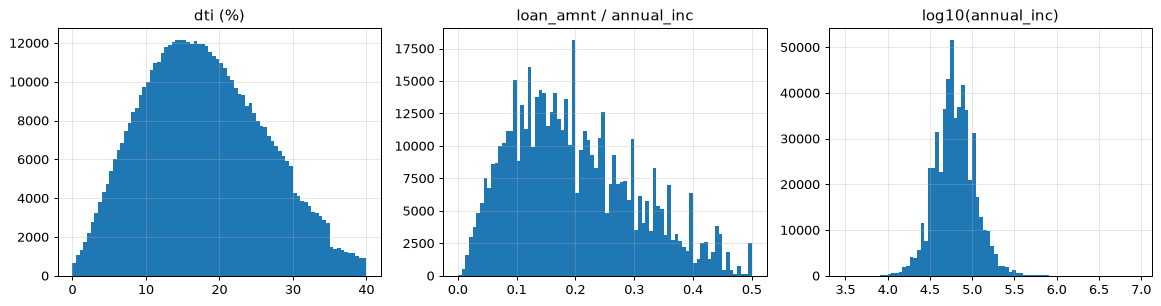

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(dev["dti"], bins=80, color="tab:blue")
axes[0].set_title("dti (%)")
axes[1].hist(dev["loan_to_income"], bins=80, color="tab:blue")
axes[1].set_title("loan_amnt / annual_inc")
axes[2].hist(np.log10(dev["annual_inc"]), bins=80, color="tab:blue")
axes[2].set_title("log10(annual_inc)")
fig.tight_layout()
dev[["dti", "loan_to_income", "annual_inc", "fico_range_low", "revol_bal"]].describe(
    percentiles=[0.01, 0.5, 0.99]
).T

**Takeaway.** Hard edges in the data are LC's approval rules: DTI stops just below 40%,
loan-to-income stops at 0.5, and FICO starts around 660. Every loan in the data passed LC's
underwriting. Rejected applicants are absent, so the model learns risk *inside LC's approval
box* and says nothing reliable outside it. This is the **reject-inference** limitation of any
model built on approved-only data. It will be documented in the model card, and inputs
outside the observed policy range can be flagged by the API.

Heavy right tails (income up to $9M, revolving balance up to $2.9M) need no capping or log
transform for tree models, which split on rank order. Only the logistic baseline gets
log/clip preprocessing.

## 7. Redundancy and stability

In [10]:
numeric_inputs = [f.name for f in schema.APPLICATION_FIELDS if f.kind == "numeric"]
corr = dev[numeric_inputs].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"{(upper > 0.8).sum()} field pairs with |Spearman| > 0.8")
upper.sort_values(ascending=False).head(10).rename("abs_spearman").to_frame()

18 field pairs with |Spearman| > 0.8


abs_spearman
open_acc                 num_sats                               0.998
num_actv_rev_tl          num_rev_tl_bal_gt_0                    0.989
tot_cur_bal              tot_hi_cred_lim                        0.973
                         avg_cur_bal                            0.932
avg_cur_bal              tot_hi_cred_lim                        0.887
mths_since_recent_bc_dlq mths_since_recent_revol_delinq         0.884
mths_since_last_delinq   mths_since_recent_revol_delinq         0.871
total_rev_hi_lim         total_bc_limit                         0.865
bc_util                  percent_bc_gt_75                       0.858
total_bal_ex_mort        total_il_high_credit_limit             0.849

In [11]:
train, validation = dev[dev["split"] == "train"], dev[dev["split"] == "validation"]
drift = psi_table(train, validation, schema.ALL_INPUT_FIELDS)
print(f"max PSI train -> validation: {drift['psi'].max():.3f} ({drift.loc[0, 'field']})")
drift.head(10)

max PSI train -> validation: 0.057 (verification_status)


,field,psi
0,verification_status,0.057
1,mths_since_last_record,0.047
2,inq_last_6mths,0.037
3,sub_grade,0.030
4,percent_bc_gt_75,0.027
5,num_bc_tl,0.026
6,num_tl_op_past_12m,0.025
7,dti,0.024
8,revol_util,0.021
9,acc_open_past_24mths,0.020


**Takeaway.** Several bureau fields are near-duplicates: `open_acc` and `num_sats` have
ρ ≈ 0.998, and 18 pairs exceed 0.8. Trees cope with that, and dropping fields by hand before
validation (as v1 did) throws information away. The logistic baseline uses L2
regularization to handle it.

**Every input is stable between the train and validation years (all PSI < 0.1)**, yet the
default rate and the risk behind each grade moved (sections 1–2). The applicant population
looks the same on paper while outcomes shift. That has a direct consequence for monitoring:
**input-drift monitoring alone would not have caught this change.** The monitoring stage has
to track realized default rates against predictions once labels arrive, not only input PSI.

## 8. From findings to modeling decisions

| Finding | Decision (M2) |
|---|---|
| Default rate rises over time | Fit probability calibration on the most recent labeled year (2015 validation) |
| `sub_grade` is the strongest single input, but its meaning drifts | Model A (no LC rating) vs Model B (+ `sub_grade`) on identical splits and tuning budgets |
| Signal is spread over many weak, related bureau fields | Gradient-boosted trees (XGBoost) as the main model; logistic regression as the baseline |
| Main drivers are monotonic and intuitive | Try monotonic constraints and report the cost in AUC |
| Missing values carry signal (both directions) | Keep nulls for XGBoost; add missing-value indicators for the logistic baseline |
| Data covers approved loans only | Document reject inference as a limitation; flag inputs outside the observed policy range |
| Inputs are stable while outcomes shift | Monitor realized vs predicted default, not only input PSI |
| `verification_status` and `addr_state` encode LC selection and geography | Keep, and report their contribution with a fairness note |